In [1]:
# ============================================================
# LABORATORIO DE COMPETENCIA Y MICROESTRUCTURA DEL MERCADO P2P
# Notebook 02: Estacionariedad (ADF) y Causalidad (Stackelberg / Bertrand)
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
import warnings
warnings.filterwarnings("ignore")

ruta_clean = Path("../data_clean")

def evaluar_estacionariedad_adf(df_vwap, nombre_bloque):
    """
    Aplica el test Dickey-Fuller Aumentado (ADF) en niveles (P_t) y 
    en primeras diferencias (Delta P_t), descartando series de varianza nula.
    """
    resultados = []
    for vendedor in df_vwap.columns:
        serie_nivel = df_vwap[vendedor].dropna()
        serie_diff = serie_nivel.diff().dropna()
        
        # Filtro anti-InfeasibleTestError (descarta anuncios congelados con varianza ~ 0)
        if serie_nivel.std() < 1e-6 or serie_diff.std() < 1e-6:
            continue
            
        p_nivel = adfuller(serie_nivel, autolag='AIC')[1]
        p_diff = adfuller(serie_diff, autolag='AIC')[1]
        
        resultados.append({
            'Bloque': nombre_bloque,
            'Vendedor': vendedor,
            'P_Valor_Niveles': p_nivel,
            'Estacionaria_Niveles': p_nivel < 0.05,
            'P_Valor_Diff': p_diff,
            'Estacionaria_Diff': p_diff < 0.05
        })
    return pd.DataFrame(resultados)

# Cargar matrices limpias del Notebook 01
bloques = {
    'Epoca1_SELL': pd.read_csv(ruta_clean / "vwap_diario_epoca1_sell.csv", index_col=0, parse_dates=True),
    'Epoca2_SELL': pd.read_csv(ruta_clean / "vwap_diario_epoca2_sell.csv", index_col=0, parse_dates=True),
    'Epoca1_BUY':  pd.read_csv(ruta_clean / "vwap_diario_epoca1_buy.csv", index_col=0, parse_dates=True),
    'Epoca2_BUY':  pd.read_csv(ruta_clean / "vwap_diario_epoca2_buy.csv", index_col=0, parse_dates=True),
}

resumen_adf = pd.concat([evaluar_estacionariedad_adf(df, nom) for nom, df in bloques.items()], ignore_index=True)

# Tabla resumen para el Paper Académico
tabla_paper_adf = resumen_adf.groupby('Bloque').agg(
    Vendedores_Activos=('Vendedor', 'count'),
    Estacionarias_en_Niveles=('Estacionaria_Niveles', 'sum'),
    Estacionarias_en_Diferencias=('Estacionaria_Diff', 'sum'),
    P_Valor_Medio_Diff=('P_Valor_Diff', 'mean')
)
display(tabla_paper_adf)

,Vendedores_Activos,Estacionarias_en_Niveles,Estacionarias_en_Diferencias,P_Valor_Medio_Diff
Bloque,,,,
Epoca1_BUY,17,1,17,0.000002
Epoca1_SELL,23,0,23,0.001698
Epoca2_BUY,33,0,33,0.000077
Epoca2_SELL,34,0,34,0.000009


In [3]:
# ============================================================
# 2. MODELOS DE TRANSMISIÓN DE PRECIOS: STACKELBERG VS BERTRAND
# ============================================================

def analizar_competencia_granger(nombre_bloque, tipo_orden, epoca_num, max_lag=4, min_cambios=5):
    df_vwap = pd.read_csv(ruta_clean / f"vwap_diario_epoca{epoca_num}_{tipo_orden}.csv", index_col=0, parse_dates=True)
    df_excl = pd.read_csv(ruta_clean / f"mercado_excl_epoca{epoca_num}_{tipo_orden}.csv", index_col=0, parse_dates=True)
    
    # Transformar a primeras diferencias (Series I(0) estacionarias)
    d_vwap = df_vwap.diff().dropna()
    d_excl = df_excl.diff().dropna()
    
    resultados = []
    for vendedor in d_vwap.columns:
        s_vend = d_vwap[vendedor]
        s_merc = d_excl[vendedor]
        
        # Filtro de microestructura: descartar anuncios "zombis" o congelados.
        # Exigimos que el vendedor haya ajustado su precio en al menos 'min_cambios' días.
        dias_con_cambio = int((s_vend.abs() > 1e-6).sum())
        if dias_con_cambio < min_cambios or s_merc.std() < 1e-6:
            continue
            
        try:
            # 1. Sentido Stackelberg: ¿El vendedor causa/anticipa al mercado excluyente?
            data_stack = pd.concat([s_merc, s_vend], axis=1).dropna()
            test_stack = grangercausalitytests(data_stack, maxlag=max_lag, verbose=False)
            p_stack_lags = {lag: test_stack[lag][0]['ssr_ftest'][1] for lag in range(1, max_lag + 1)}
            mejor_lag_stack = min(p_stack_lags, key=p_stack_lags.get)
            min_p_stack = p_stack_lags[mejor_lag_stack]
            
            # 2. Sentido Bertrand (Reacción): ¿El mercado excluyente causa al vendedor?
            data_bert = pd.concat([s_vend, s_merc], axis=1).dropna()
            test_bert = grangercausalitytests(data_bert, maxlag=max_lag, verbose=False)
            p_bert_lags = {lag: test_bert[lag][0]['ssr_ftest'][1] for lag in range(1, max_lag + 1)}
            mejor_lag_bert = min(p_bert_lags, key=p_bert_lags.get)
            min_p_bert = p_bert_lags[mejor_lag_bert]
            
            resultados.append({
                'Bloque': nombre_bloque,
                'Vendedor': vendedor,
                'Dias_Cambio_Precio': dias_con_cambio,
                'Lag_Stackelberg': mejor_lag_stack,
                'P_Stackelberg': min_p_stack,
                'Es_Lider_Stackelberg': min_p_stack < 0.05,
                'Lag_Bertrand_Reaccion': mejor_lag_bert,
                'P_Bertrand_Reaccion': min_p_bert,
                'Reacciona_al_Mercado': min_p_bert < 0.05
            })
        except Exception:
            # Si alguna ventana rezagada queda con varianza cero, se descarta con seguridad
            continue
            
    df_res = pd.DataFrame(resultados).sort_values('P_Stackelberg').reset_index(drop=True)
    return df_res

# Ejecutar para las 4 combinaciones y consolidar
ranking_total = pd.concat([
    analizar_competencia_granger('Epoca1_SELL', 'sell', 1),
    analizar_competencia_granger('Epoca2_SELL', 'sell', 2),
    analizar_competencia_granger('Epoca1_BUY',  'buy',  1),
    analizar_competencia_granger('Epoca2_BUY',  'buy',  2)
], ignore_index=True)

# Resumen estructural por Época (Evidencia directa para la Pregunta de Investigación)
resumen_regimen = ranking_total.groupby('Bloque').agg(
    Total_Evaluados=('Vendedor', 'count'),
    Lideres_Stackelberg=('Es_Lider_Stackelberg', 'sum'),
    Seguidores_que_Reaccionan=('Reacciona_al_Mercado', 'sum')
)
display(resumen_regimen)

# Mostrar Top 10 Líderes en Época 2 (BUY y SELL)
print("\n--- TOP 10 LÍDERES PREDICTIVOS: ÉPOCA 2 (BUY) ---")
display(ranking_total[ranking_total['Bloque'] == 'Epoca2_BUY'].head(10))

print("\n--- TOP 10 LÍDERES PREDICTIVOS: ÉPOCA 2 (SELL) ---")
display(ranking_total[ranking_total['Bloque'] == 'Epoca2_SELL'].head(10))

# Exportar resultados precalculados para que Streamlit Cloud los lea al instante sin consumir RAM
ranking_total.to_csv(ruta_clean / "resultados_granger_stackelberg_bertrand.csv", index=False)
resumen_adf.to_csv(ruta_clean / "resultados_estacionariedad_adf.csv", index=False)
print("\nArchivos exportados exitosamente a ../data_clean/")

,Total_Evaluados,Lideres_Stackelberg,Seguidores_que_Reaccionan
Bloque,,,
Epoca1_BUY,16,5,2
Epoca1_SELL,21,13,11
Epoca2_BUY,33,24,24
Epoca2_SELL,33,19,22



--- TOP 10 LÍDERES PREDICTIVOS: ÉPOCA 2 (BUY) ---


,Bloque,Vendedor,Dias_Cambio_Precio,Lag_Stackelberg,P_Stackelberg,Es_Lider_Stackelberg,Lag_Bertrand_Reaccion,P_Bertrand_Reaccion,Reacciona_al_Mercado
70,Epoca2_BUY,P2P-AJAG,146,2,3.597874e-08,True,2,0.001559,True
71,Epoca2_BUY,issei300,126,2,2.335775e-05,True,1,0.021891,True
72,Epoca2_BUY,GermanBol,159,2,7.129772e-05,True,1,0.000326,True
73,Epoca2_BUY,_FastCoins_,157,2,8.229990e-05,True,1,0.030005,True
74,Epoca2_BUY,Lion_Liquidity,115,4,1.023330e-04,True,4,0.000137,True
75,Epoca2_BUY,MarceCrypto77,164,2,1.270896e-04,True,1,0.028909,True
76,Epoca2_BUY,A-Ri-eL,146,4,3.584960e-04,True,2,0.000296,True
77,Epoca2_BUY,MegaCrypToE,159,2,4.500065e-04,True,1,0.006255,True
78,Epoca2_BUY,ZULMA_PEXOTINHO,117,2,8.572120e-04,True,1,0.123712,False
79,Epoca2_BUY,FastG0ZU,121,2,1.257907e-03,True,3,0.021576,True



--- TOP 10 LÍDERES PREDICTIVOS: ÉPOCA 2 (SELL) ---


,Bloque,Vendedor,Dias_Cambio_Precio,Lag_Stackelberg,P_Stackelberg,Es_Lider_Stackelberg,Lag_Bertrand_Reaccion,P_Bertrand_Reaccion,Reacciona_al_Mercado
21,Epoca2_SELL,FastG0ZU,126,4,6.304906e-13,True,3,0.067919,False
22,Epoca2_SELL,GermanBol,167,2,3.072714e-07,True,2,0.000939,True
23,Epoca2_SELL,MegaCrypToE,161,2,3.873697e-07,True,3,0.421552,False
24,Epoca2_SELL,Te_Gateo,151,2,6.604420e-07,True,4,0.000607,True
25,Epoca2_SELL,_FastCoins_,160,3,1.735032e-06,True,4,0.300702,False
26,Epoca2_SELL,GUERRERO_07,145,2,6.936854e-06,True,2,0.000095,True
27,Epoca2_SELL,P2P-AJAG,141,2,1.115970e-05,True,4,0.000054,True
28,Epoca2_SELL,Scorpions09,153,4,2.865636e-05,True,2,0.187854,False
29,Epoca2_SELL,KatherineGM__Trader,143,3,1.409799e-04,True,1,0.082440,False
30,Epoca2_SELL,P2P-84e74cxc,10,4,5.547962e-04,True,3,0.400459,False



Archivos exportados exitosamente a ../data_clean/


--- CENTRALIDAD EN LA RED DE BERTRAND: ÉPOCA 2 (BUY) ---


,Bloque,Vendedor,Influencia_Saliente_OutDegree,P_Valor_Medio_Emision,Lag_Medio_Emision,Sensibilidad_Entrante_InDegree,Indice_Liderazgo_Neto
0,Epoca2_BUY,_FastCoins_,9,0.000146,2.333333,8,1
1,Epoca2_BUY,Lion_Liquidity,9,0.000282,3.444444,9,0
2,Epoca2_BUY,MarceCrypto77,9,0.001591,2.777778,9,0
3,Epoca2_BUY,ZULMA_PEXOTINHO,9,0.002042,3.333333,9,0
4,Epoca2_BUY,MegaCrypToE,9,0.005088,2.888889,8,1
5,Epoca2_BUY,issei300,9,0.005533,2.888889,6,3
6,Epoca2_BUY,GermanBol,8,0.014598,3.000000,6,2
7,Epoca2_BUY,P2P-AJAG,7,0.024901,3.222222,8,-1
8,Epoca2_BUY,A-Ri-eL,7,0.085968,2.888889,9,-2
9,Epoca2_BUY,FastG0ZU,5,0.070123,2.333333,9,-4



--- CENTRALIDAD EN LA RED DE BERTRAND: ÉPOCA 2 (SELL) ---


,Bloque,Vendedor,Influencia_Saliente_OutDegree,P_Valor_Medio_Emision,Lag_Medio_Emision,Sensibilidad_Entrante_InDegree,Indice_Liderazgo_Neto
0,Epoca2_SELL,FastG0ZU,9,0.000011,3.000000,7,2
1,Epoca2_SELL,MegaCrypToE,9,0.000035,2.777778,7,2
2,Epoca2_SELL,_FastCoins_,9,0.000823,2.333333,6,3
3,Epoca2_SELL,KatherineGM__Trader,9,0.003819,2.555556,9,0
4,Epoca2_SELL,P2P-AJAG,9,0.005975,2.444444,9,0
5,Epoca2_SELL,GUERRERO_07,8,0.009394,2.111111,8,0
6,Epoca2_SELL,Scorpions09,8,0.011971,2.222222,8,0
7,Epoca2_SELL,Te_Gateo,8,0.011971,3.333333,9,-1
8,Epoca2_SELL,Liacripto,6,0.042012,2.777778,9,-3
9,Epoca2_SELL,GermanBol,5,0.043633,2.888889,8,-3


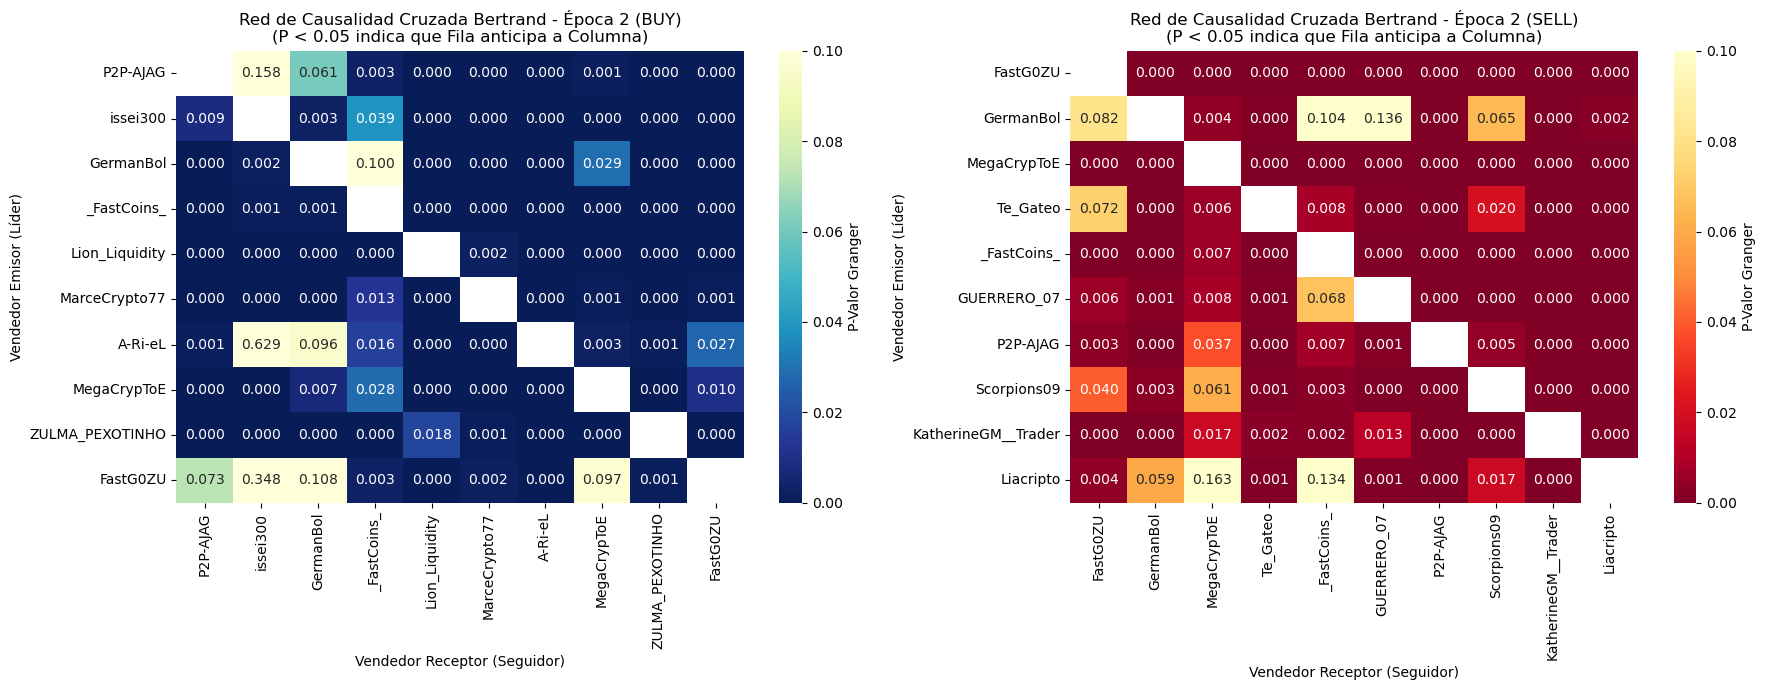

Matrices de red de Bertrand exportadas exitosamente a ../data_clean/


In [4]:
# ============================================================
# 3. MATRIZ DE CAUSALIDAD CRUZADA (N x N) - MODELO DE BERTRAND
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

def construir_red_bertrand(tipo_orden, epoca_num, top_n=10, max_lag=4):
    """
    Evalúa la causalidad de Granger par-a-par (i -> j) entre los Top N líderes
    de una época y modalidad, calculando métricas de centralidad de red (Out-Degree e In-Degree).
    """
    bloque_nombre = f"Epoca{epoca_num}_{tipo_orden.upper()}"
    df_vwap = pd.read_csv(ruta_clean / f"vwap_diario_epoca{epoca_num}_{tipo_orden.lower()}.csv", index_col=0, parse_dates=True)
    
    # Seleccionar el Top N de líderes activos identificados en la Celda 2 (con al menos 30 días de cambio de precio)
    sub_ranking = ranking_total[
        (ranking_total['Bloque'] == bloque_nombre) & 
        (ranking_total['Dias_Cambio_Precio'] >= 30)
    ].head(top_n)
    
    lista_top = sub_ranking['Vendedor'].tolist()
    d_vwap = df_vwap[lista_top].diff().dropna()
    
    matriz_p = pd.DataFrame(np.nan, index=lista_top, columns=lista_top)
    relaciones = []
    
    for emisor in lista_top:
        for receptor in lista_top:
            if emisor == receptor:
                continue
            # En grangercausalitytests: columna 0 es la causada (receptor), columna 1 es la causante (emisor)
            data_pair = pd.concat([d_vwap[receptor], d_vwap[emisor]], axis=1).dropna()
            try:
                test = grangercausalitytests(data_pair, maxlag=max_lag, verbose=False)
                p_lags = {lag: test[lag][0]['ssr_ftest'][1] for lag in range(1, max_lag + 1)}
                mejor_lag = min(p_lags, key=p_lags.get)
                min_p = p_lags[mejor_lag]
                
                matriz_p.loc[emisor, receptor] = min_p
                relaciones.append({
                    'Bloque': bloque_nombre,
                    'Vendedor_Emisor': emisor,
                    'Vendedor_Receptor': receptor,
                    'Mejor_Lag': mejor_lag,
                    'P_Valor': min_p,
                    'Causa_Significativa': min_p < 0.05
                })
            except Exception:
                continue
                
    df_rel = pd.DataFrame(relaciones)
    
    # Calcular métricas de red competitiva por vendedor
    out_deg = df_rel.groupby('Vendedor_Emisor').agg(
        Influencia_Saliente_OutDegree=('Causa_Significativa', 'sum'),
        P_Valor_Medio_Emision=('P_Valor', 'mean'),
        Lag_Medio_Emision=('Mejor_Lag', 'mean')
    )
    in_deg = df_rel.groupby('Vendedor_Receptor').agg(
        Sensibilidad_Entrante_InDegree=('Causa_Significativa', 'sum')
    )
    
    resumen_nodos = out_deg.join(in_deg)
    resumen_nodos['Indice_Liderazgo_Neto'] = (
        resumen_nodos['Influencia_Saliente_OutDegree'] - resumen_nodos['Sensibilidad_Entrante_InDegree']
    )
    resumen_nodos = resumen_nodos.sort_values(
        ['Influencia_Saliente_OutDegree', 'P_Valor_Medio_Emision'], 
        ascending=[False, True]
    ).reset_index().rename(columns={'Vendedor_Emisor': 'Vendedor'})
    resumen_nodos.insert(0, 'Bloque', bloque_nombre)
    
    return matriz_p, df_rel, resumen_nodos

# Ejecutar matriz cruzada para Época 2 (BUY y SELL)
matriz_p_buy2, rel_buy2, nodos_buy2 = construir_red_bertrand('buy', 2, top_n=10)
matriz_p_sell2, rel_sell2, nodos_sell2 = construir_red_bertrand('sell', 2, top_n=10)

print("--- CENTRALIDAD EN LA RED DE BERTRAND: ÉPOCA 2 (BUY) ---")
display(nodos_buy2)

print("\n--- CENTRALIDAD EN LA RED DE BERTRAND: ÉPOCA 2 (SELL) ---")
display(nodos_sell2)

# Visualización: Mapas de Calor de Transmisión Bilateral de Precios (Filas = Emisor, Columnas = Receptor)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    matriz_p_buy2, annot=True, fmt=".3f", cmap="YlGnBu_r", 
    vmin=0, vmax=0.10, cbar_kws={'label': 'P-Valor Granger'}, ax=axes[0]
)
axes[0].set_title("Red de Causalidad Cruzada Bertrand - Época 2 (BUY)\n(P < 0.05 indica que Fila anticipa a Columna)")
axes[0].set_xlabel("Vendedor Receptor (Seguidor)")
axes[0].set_ylabel("Vendedor Emisor (Líder)")

sns.heatmap(
    matriz_p_sell2, annot=True, fmt=".3f", cmap="YlOrRd_r", 
    vmin=0, vmax=0.10, cbar_kws={'label': 'P-Valor Granger'}, ax=axes[1]
)
axes[1].set_title("Red de Causalidad Cruzada Bertrand - Época 2 (SELL)\n(P < 0.05 indica que Fila anticipa a Columna)")
axes[1].set_xlabel("Vendedor Receptor (Seguidor)")
axes[1].set_ylabel("Vendedor Emisor (Líder)")

plt.tight_layout()
plt.show()

# Exportar tablas de red para Streamlit Cloud y el Paper
pd.concat([rel_buy2, rel_sell2], ignore_index=True).to_csv(ruta_clean / "red_bertrand_pares_epoca2.csv", index=False)
pd.concat([nodos_buy2, nodos_sell2], ignore_index=True).to_csv(ruta_clean / "red_bertrand_nodos_epoca2.csv", index=False)
print("Matrices de red de Bertrand exportadas exitosamente a ../data_clean/")